# Σ・T・B の動径分布アニメーション

thesis.ipynb の静止図 (Σ: 面密度のセル, T: 温度のセル, B: 磁場のセル) と同じフォントサイズ・線幅・凡例で,
Σ だけ / T だけ / B だけ のアニメーションを作る.

- 赤線: 初期 (0 yr) の分布 (`show_initial = True` のとき), 青線: 各フレームの時刻の分布
- 出力は GIF (Pillow). ffmpeg が無いので mp4 は使わない.
- file_gas 列: 0:r_cen 1:sigmag 2:sigmad_tot 3:sigmad_vapor 12:T / file_B 列: 2:B

In [23]:
import os
import re
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.lines import Line2D
from IPython.display import Image, display

AU = 1.495979e+13

# ==================================
# 設定
# ==================================
outdir = "/mnt/hdd/shimokawa"
resultdir = "/beta4_5zeta1e16"
fig_dir = "./fig/b4_5z15"
model_label = "z15"      # 図のタイトル ("" で非表示)

dt_frame = 1.0e3           # フレーム間隔 [yr] (この刻みに最も近いスナップショットを使う)
t_max = 1.0e5               # この時刻 [yr] までを使う (None で全て) None
max_frames = 200           # フレーム数の上限 (超えたら等間隔に間引く)
fps = 8
dpi = 120
show_initial = True        # 初期 (0 yr) の分布を赤線で残すか

r_min, r_max = 0.5, 3.0e2
figsize = (6, 5)           # thesis.ipynb の 2x2 (12, 10) の 1 枠と同じ大きさ

os.makedirs(fig_dir, exist_ok=True)

In [24]:
# ==================================
# スナップショットの選択と読込
# ==================================
path_gas = outdir + resultdir
path_B = outdir + resultdir + "_B"

years_all = sorted(int(m.group(1)) for f in os.listdir(path_gas)
                   if (m := re.fullmatch(r"out(\d+)_gas", f)))
years_all = [y for y in years_all
             if os.path.exists("{}/out{}_B".format(path_B, y)) and (t_max is None or y <= t_max)]

ya = np.array(years_all, dtype=float)
targets = np.arange(0.0, ya[-1] + 0.5 * dt_frame, dt_frame)
idx = sorted({int(np.argmin(np.abs(ya - tt))) for tt in targets})
if len(idx) > max_frames:
    idx = sorted({idx[i] for i in np.linspace(0, len(idx) - 1, max_frames).round().astype(int)})
years = [years_all[i] for i in idx]

frames = []
for year in years:
    gas = np.loadtxt("{}/out{}_gas".format(path_gas, year), usecols=(0, 1, 2, 3, 12)).T
    B = np.loadtxt("{}/out{}_B".format(path_B, year), usecols=(2,))
    frames.append({
        "t": float(year),
        "sigmag": gas[1],
        "sigmad": gas[2] - gas[3],
        "T": gas[4],
        "B": B,
    })
X = gas[0] / AU

print("{} frames : {} yr - {} yr".format(len(frames), years[0], years[-1]))

101 frames : 0 yr - 100000 yr


In [21]:
# ==================================
# 共通の関数
# ==================================
def time_label(t, style):
    # thesis.ipynb の各図の凡例の書式に合わせる
    #   "sigma": $0 \ \rm{yr}$ , $1.00\times10^{3}\ \rm{yr}$
    #   "T"    : $0.0 \rm{[yr]}$ , $1.00 \times 10^{3}\rm{[yr]}$
    #   "B"    : $0.0 \rm{yr}$ , $1.00\times 10^{3} \rm{yr}$
    if t == 0:
        return {"sigma": r"$0 \ \rm{yr}$", "T": r"$0.0 \rm{[yr]}$", "B": r"$0.0 \rm{yr}$"}[style]
    n = int(np.floor(np.log10(t)))
    a = t / 10.0**n
    if round(a, 2) >= 10.0:
        a, n = a / 10.0, n + 1
    if style == "sigma":
        return r"${:.2f}\times10^{{{}}}\ \rm{{yr}}$".format(a, n)
    if style == "T":
        return r"${:.2f} \times 10^{{{}}}\rm{{[yr]}}$".format(a, n)
    return r"${:.2f}\times 10^{{{}}} \rm{{yr}}$".format(a, n)


def setup_ax(ax, ylabel, ylim):
    ax.set_xlabel(r"$ \rm{r} \ \rm{[au]}$", fontsize=15)
    ax.set_ylabel(ylabel, fontsize=15)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(r_min, r_max)
    ax.set_ylim(*ylim)
    ax.tick_params(labelsize=15)
    if model_label:
        ax.set_title(model_label, fontsize=15)


def animate_profile(key, ylabel, ylim, label_style, out_name, dust_key=None, decorate=None):
    # key: 実線で描く量, dust_key: 点線で描く量 (Σ のダスト), decorate: 固定の補助線などを描く関数
    fig, ax = plt.subplots(figsize=figsize)
    setup_ax(ax, ylabel, ylim)
    if decorate is not None:
        decorate(ax)

    if show_initial:
        ax.plot(X, frames[0][key], color="red", linestyle="solid", lw=3)
        if dust_key is not None:
            ax.plot(X, frames[0][dust_key], color="red", linestyle="dotted", lw=3)
    line, = ax.plot([], [], color="blue", linestyle="solid", lw=3)
    line_d = ax.plot([], [], color="blue", linestyle="dotted", lw=3)[0] if dust_key is not None else None

    # ---- 凡例 (時間=色) : 毎フレーム作り直す ----
    h_init = Line2D([0], [0], color="red", lw=3, label=time_label(frames[0]["t"], label_style))
    h_now = Line2D([0], [0], color="blue", lw=3)
    handles = ([h_init] if show_initial else []) + [h_now]

    plt.tight_layout()

    def update(i):
        f = frames[i]
        line.set_data(X, f[key])
        if line_d is not None:
            line_d.set_data(X, f[dust_key])
        h_now.set_label(time_label(f["t"], label_style))
        ax.legend(handles=handles, fontsize=12, loc="upper right")

    anim = animation.FuncAnimation(fig, update, frames=len(frames), blit=False)
    out_path = os.path.join(fig_dir, out_name)
    anim.save(out_path, writer=animation.PillowWriter(fps=fps), dpi=dpi)
    plt.close(fig)
    print("wrote", out_path)
    display(Image(filename=out_path))

wrote ./fig/b4z15/anim_sigma.gif


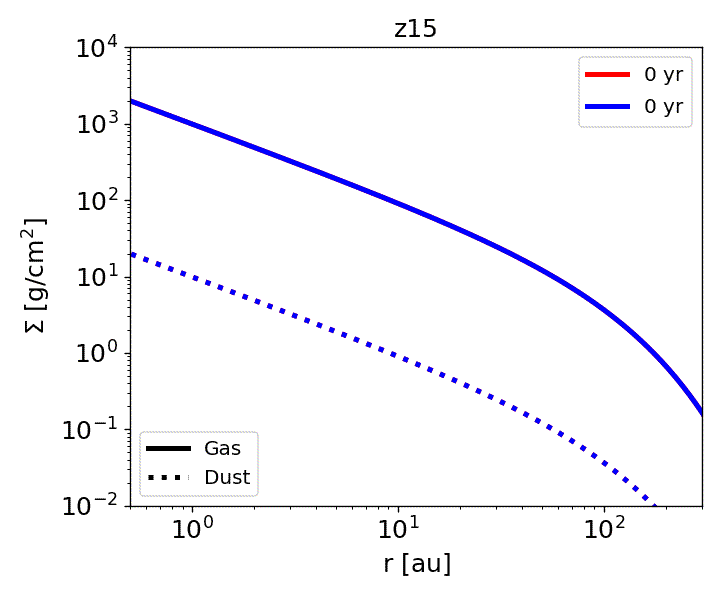

In [15]:
# ==================================
# Σ (実線=ガス, 点線=ダスト)
# ==================================
def decorate_sigma(ax):
    # ---- 凡例2 (種類=線種) : 固定 ----
    legend_species = [
        Line2D([0], [0], color="black", lw=3, linestyle="solid",  label="Gas"),
        Line2D([0], [0], color="black", lw=3, linestyle="dotted", label="Dust"),
    ]
    ax.add_artist(ax.legend(handles=legend_species, fontsize=12, loc="lower left"))

animate_profile("sigmag", r"$\Sigma \ \rm{[g/cm^2]}$", (1.0e-2, 1.0e4), "sigma",
                "anim_sigma.gif", dust_key="sigmad", decorate=decorate_sigma)

wrote ./fig/b4z17/anim_T.gif


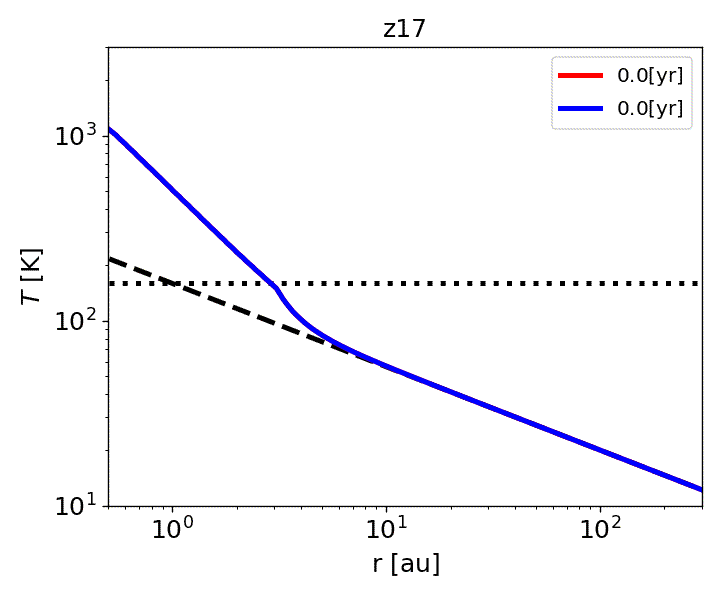

In [21]:
# ==================================
# 中心面温度 T
# ==================================
def decorate_T(ax):
    T_analytic = 20.0 * (X / 100.0)**-0.45
    ax.plot(X, T_analytic, color="black", lw=3, linestyle="dashed")
    ax.plot(X, np.full_like(X, 1.6e2), color="black", lw=3, linestyle="dotted")

animate_profile("T", r"$ T \ \rm{[K]}  $", (1.0e1, 3.0e3), "T",
                "anim_T.gif", decorate=decorate_T)

wrote ./fig/b4z17/anim_B.gif


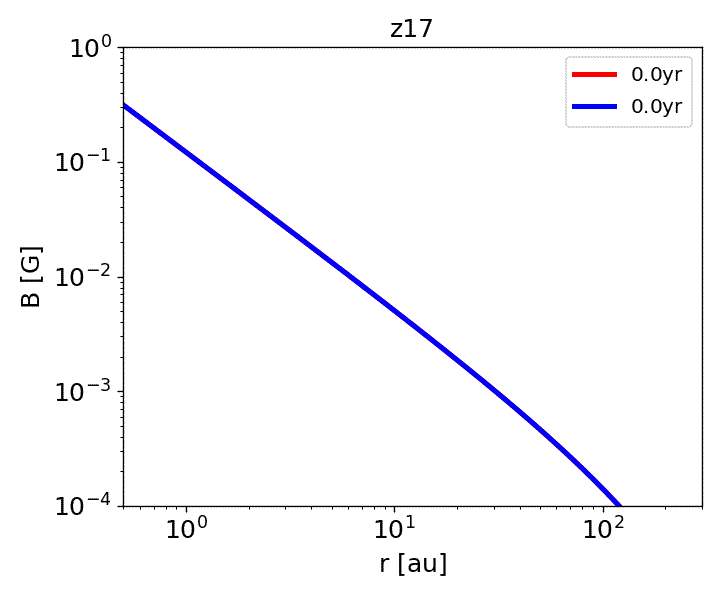

In [23]:
# ==================================
# 磁場 B
# ==================================
animate_profile("B", r"$ \rm{B} \ \rm{[G]}$", (1.0e-4, 1.0e0), "B",
                "anim_B.gif")

In [ ]:
# ==================================
# ダストの (r, a) 分布 (縦軸: ダストサイズ a_d, 横軸: r, カラーバー: 各サイズビンのダスト面密度)
# thesis.ipynb の cell 11 (ダストマップ) と同じ体裁:
#   カラーマップ rainbow, LogNorm(1e-10, 1e2), |Sigma_d| <= 1e-15 のビンは描かない, ラベル 15, 目盛り 15
# ダストファイル out<N>: 3行目 = ダスト半径 [cm], 6行目以降 = r_cen, Sigma_d(bin0), Sigma_d(bin1), ...
# 上のセルの years (フレームの時刻), path_gas, fig_dir, model_label, r_min, r_max, fps, dpi, time_label を使う
# ダストファイルが無い時刻は飛ばす
# ==================================
from matplotlib.colors import LogNorm

dust_vmin, dust_vmax = 1.0e-10, 1.0e2    # カラーバーの範囲
a_min, a_max = 1.0e-5, 1.0e3             # 縦軸の範囲 [cm]
figsize_dust = (7.5, 5)                  # カラーバーの分だけ横に広げる

dust_years = [y for y in years if os.path.exists("{}/out{}".format(path_gas, y))]
with open("{}/out{}".format(path_gas, dust_years[0])) as f:
    header = [f.readline() for _ in range(3)]
dradius = np.array([float(x) for x in header[2].split()])

dust_frames = []
for year in dust_years:
    data = np.loadtxt("{}/out{}".format(path_gas, year), skiprows=5).T
    sigmad = data[1:]
    dust_frames.append((float(year), np.where(np.abs(sigmad) > 1.0e-15, sigmad, np.nan)))
X_d = data[0] / AU

print("{} frames : {} yr - {} yr".format(len(dust_frames), dust_years[0], dust_years[-1]))

fig, ax = plt.subplots(figsize=figsize_dust)
pm = ax.pcolormesh(X_d, dradius, dust_frames[0][1], cmap="rainbow",
                   norm=LogNorm(vmin=dust_vmin, vmax=dust_vmax), shading="nearest")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"$ r \ \mathrm{[au]} $", fontsize=15)
ax.set_ylabel(r"$ a_d \ \mathrm{[cm]} $", fontsize=15)
ax.set_xlim(r_min, r_max)
ax.set_ylim(a_min, a_max)
ax.tick_params(labelsize=15)
title = ax.set_title("", fontsize=15)

cbar = fig.colorbar(pm, ax=ax)
cbar.set_label(r"$ \frac{d\Sigma_d(m)}{d\ln m}  $", fontsize=15)
cbar.ax.tick_params(labelsize=12)
plt.tight_layout()

def update_dust(i):
    t, sigmad = dust_frames[i]
    pm.set_array(sigmad)
    title.set_text(time_label(t, "sigma"))
    # title.set_text((model_label + " : " if model_label else "") + time_label(t, "sigma"))

anim = animation.FuncAnimation(fig, update_dust, frames=len(dust_frames), blit=False)
out_path = os.path.join(fig_dir, "anim_dust.gif")
anim.save(out_path, writer=animation.PillowWriter(fps=fps), dpi=dpi)
plt.close(fig)
print("wrote", out_path)
display(Image(filename=out_path))


101 frames : 0 yr - 100000 yr
